# Предсказание оценки игры в Steam по её характеристикам

Датасет: [Steam Games Dataset](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset) (FronkonGames, Kaggle)

In [111]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

# 0. Постановка задачи

В Steam у каждой игры есть пользовательские отзывы: каждый отзыв может быть либо положительным, либо отрицательным. По доле положительных отзывов Steam присваивает игре итоговую оценку.

**Задача:** по данным об игре в Steam (цена, жанры, платформы, поддерживаемые языки и т. д.) определить, будет ли доля положительных отзывов **не меньше 70%**; это соответствует задаче бинарной классификации:

$$
y = 
\begin{cases}
1, & \text{если } \dfrac{\text{Positive}}{\text{Positive} + \text{Negative}} \ge 0.7, \\
0, & \text{иначе}
\end{cases}
$$

Для обучения и проверки используем только игры, у которых не меньше 10 отзывов: при слишком малом числе отзывов оценка игры не является показательной.

Также столбцы `Positive` и `Negative` непосредственно задают ответ, поэтому нельзя использовать их как признаки. Это же относится к столбцам, значения в которых вычислены на основе отзывов (например, `User score`, `Score rank`). Эти столбцы будут исключены из признаков перед обучением.

# 1. Чтение данных

Датасет загружается с Kaggle с помощью библиотеки `kagglehub`:

In [112]:
import kagglehub

path = kagglehub.dataset_download('fronkongames/steam-games-dataset/versions/54')
csv_path = path + '/games.csv'

print(csv_path)

/home/quaha/.cache/kagglehub/datasets/fronkongames/steam-games-dataset/versions/54/games.csv


In [113]:
header = pd.read_csv(csv_path, nrows=0).columns.tolist()

print(len(header))

header

39


['AppID',
 'Name',
 'Release date',
 'Estimated owners',
 'Peak CCU',
 'Required age',
 'Price',
 'DiscountDLC count',
 'About the game',
 'Supported languages',
 'Full audio languages',
 'Reviews',
 'Header image',
 'Website',
 'Support url',
 'Support email',
 'Windows',
 'Mac',
 'Linux',
 'Metacritic score',
 'Metacritic url',
 'User score',
 'Positive',
 'Negative',
 'Score rank',
 'Achievements',
 'Recommendations',
 'Notes',
 'Average playtime forever',
 'Average playtime two weeks',
 'Median playtime forever',
 'Median playtime two weeks',
 'Developers',
 'Publishers',
 'Categories',
 'Genres',
 'Tags',
 'Screenshots',
 'Movies']

В строке заголовка два столбца оказались соединены в один: `DiscountDLC count`, а в самих данных это два отдельных значения (`Discount` и `DLC count`). Из-за этого в данных на одно поле больше; вероятно, это ошибка в наборе данных, соответственно, поправим это:

In [114]:
i = header.index('DiscountDLC count')
columns = header[:i] + ['Discount', 'DLC count'] + header[i+1:]

data_raw = pd.read_csv(csv_path, header=0, names=columns, index_col=False)

data_raw.shape

(125855, 40)

В таблице около 126 тысяч игр и 40 столбцов. Проверим корректность чтения данных:

In [115]:
data_raw.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [116]:
data_raw.tail()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
125850,3249570,Sotsugyo Omedeto,"Mar 1, 2026",0 - 0,0,0,8.09,0,0,A survival trial game set in an all-girls scho...,...,0,0,0,SuperLoki,SuperLoki,"Single-player,Steam Achievements,Camera Comfor...","Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
125851,2218150,Island on cloud,"Feb 24, 2026",0 - 0,0,0,0.59,0,0,"A game with a quirky art style, resembling ani...",...,0,0,0,7th Ghost,7th Ghost,"Single-player,Family Sharing","Adventure,RPG",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
125852,3788650,Rosie Planet,"Mar 1, 2026",0 - 0,0,0,12.99,0,0,Jam Packed full with Videogame Rosie Planet is...,...,0,0,0,Connor Leary,Connor Leary,"Single-player,Full controller support,Playable...","Action,Adventure,Indie",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
125853,3509140,Fear Effect 2: Retro Helix,"Feb 27, 2026",0 - 0,0,0,9.99,0,0,Return to 2048 Hong Kong in the groundbreaking...,...,0,0,0,Implicit Conversions,Limited Run Games,"Single-player,Steam Achievements,Full controll...","Action,Adventure",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
125854,4247310,Project Liminal 2,"Mar 2, 2026",0 - 0,0,0,2.51,0,0,All events and characters are fictional. Any r...,...,0,0,0,AquaHeaven Studios,TXC,"Single-player,Steam Achievements,Full controll...","Action,Adventure,Indie",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [117]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  str    
 2   Release date                125855 non-null  str    
 3   Estimated owners            125855 non-null  str    
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  str    
 10  Supported languages         125855 non-null  str    
 11  Full audio languages        125855 non-null  str    
 12  Reviews                     12181 non-null   str    
 13  Header image             

Описание столбцов:

- `AppID` - идентификатор игры в Steam
- `Name` - название
- `Release date` - дата выхода
- `Estimated owners` - оценка числа владельцев игры
- `Peak CCU` - пиковое число одновременных игроков за день до момента сбора данных
- `Required age` - возрастное ограничение
- `Price` - цена в USD
- `Discount` - текущая скидка в процентах
- `DLC count` - количество дополнений
- `About the game` - текстовое описание игры
- `Supported languages`, `Full audio languages` - языки интерфейса/субтитров и языки полной озвучки
- `Reviews` - цитаты из обзоров прессы
- `Header image`, `Website`, `Support url`, `Support email` - обложка, сайт, контакты поддержки
- `Windows`, `Mac`, `Linux` - поддерживаемые платформы
- `Metacritic score`, `Metacritic url` - оценка критиков на Metacritic
- `User score`, `Score rank` - производные от пользовательских отзывов оценки
- `Positive`, `Negative` - количество положительных и отрицательных отзывов
- `Achievements` - количество достижений
- `Recommendations` - число пользовательских рекомендаций
- `Notes` - предупреждения о содержимом (насилие и т.п.)
- `Average/Median playtime forever` - среднее/медианное время в игре за всё время
- `Average/Median playtime two weeks` - то же за последние две недели
- `Developers`, `Publishers` - разработчики и издатели
- `Categories` - внутренние категории Steam
- `Genres` - жанры
- `Tags` - пользовательские теги
- `Screenshots`, `Movies` - ссылки на скриншоты и видео

В полученном списке нет повторяющихся игр:

In [118]:
data_raw['AppID'].duplicated().sum()

np.int64(0)

Таким образом можно сделать `AppID` индексом таблицы (так как это идентификатор, а не признак игры).

In [119]:
data_raw = data_raw.set_index('AppID')

## Построение целевой переменной

Посчитаем общее количество отзывов у каждой игры:

In [120]:
n_reviews = data_raw['Positive'] + data_raw['Negative']

n_reviews.describe()

count    1.258550e+05
mean     1.183061e+03
std      3.221401e+04
min      0.000000e+00
25%      0.000000e+00
50%      6.000000e+00
75%      4.600000e+01
max      8.815087e+06
dtype: float64

In [121]:
print('Игр без отзывов:       ', (n_reviews == 0).sum())
print('Игр с  < 10 отзывами:  ', ((n_reviews > 0) & (n_reviews < 10)).sum())
print('Игр с >= 10 отзывами:  ', (n_reviews >= 10).sum())

Игр без отзывов:        42899
Игр с  < 10 отзывами:   26294
Игр с >= 10 отзывами:   56662


Больше половины игр в Steam (~55%) имеют меньше 10 отзывов, а у трети отзывов нет вовсе. Оставим только игры с не менее чем 10 отзывами
и вычислим для них долю положительных отзывов:

In [122]:
data = data_raw[n_reviews >= 10].copy()

positive_ratio = data['Positive'] / (data['Positive'] + data['Negative'])
data['Good'] = (positive_ratio >= 0.7).astype(int)

data.shape

(56662, 40)

Посмотрим на соотношение классов:

In [123]:
data['Good'].value_counts()

Good
1    40435
0    16227
Name: count, dtype: int64

In [124]:
data['Good'].value_counts(normalize=True)

Good
1    0.713618
0    0.286382
Name: proportion, dtype: float64

Около 71% игр с не менее чем 10 отзывами имеют не меньше 70% положительных отзывов; соответственно классы несбалансированы (примерно 71 : 29).

Можно заметить, что если предсказывать для всех игр класс 1, то доля ошибок будет около 29%. Этот уровень будем использовать для сравнения моделей, а из-за несбалансированности классов дополнительно будем анализировать матрицы рассогласования.

## Исключение лишних столбцов

Часть признаков напрямую связаны с тем, что будет предсказывать модель, следовательно такие столбцы следует исключить:
- `Positive`, `Negative` - по ним строится целевая переменная;
- `User score`, `Score rank` - производные от пользовательских отзывов оценки.

Также часть признаков не связана с целевым значением, такие критерии тоже следует удалить:
- `Header image` - ссылка на изображение (обложку) игры;
- `Metacritic url`, `Support url` - ссылки на иные ресурсы.


In [125]:
leak_columns = ['Positive', 'Negative', 'User score', 'Score rank']
technical_columns = ['Header image', 'Metacritic url', 'Support url']

data = data.drop(leak_columns + technical_columns, axis=1)

data.shape

(56662, 33)

# 2. Разбиение на обучающую и тестовую выборки

Отделим целевую переменную `Good` от признаков:

In [126]:
X = data.drop('Good', axis=1)
y = data['Good']

X.shape, y.shape

((56662, 32), (56662,))

Разобьём данные на обучающую и тестовую выборки в пропорции 3:1 (75% - обучающая, 25% - тестовая). Параметр `stratify=y` сохраняет соотношение классов в обеих выборках, что важно при несбалансированных классах; `random_state=42` фиксирует разбиение для воспроизводимости результатов.

Разбиение выполняется до визуализации и предобработки: все дальнейшие решения (обработка выбросов, заполнение пропусков, нормализация) будут приниматься только по обучающей выборке, иначе оценка качества на тестовой выборке окажется завышенной.

In [127]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

N_train, _ = X_train.shape
N_test,  _ = X_test.shape

N_train, N_test

(42496, 14166)

Проверим соотношение классов в обучающей и тестовой выборках:

In [128]:
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test':  y_test.value_counts(normalize=True)})

,train,test
Good,,
1,0.71362,0.71361
0,0.28638,0.28639


Соотношение классов в обеих выборках совпадает (~71% / 29%).

# 3. Визуализация и анализ данных

Анализ проводится только по обучающей выборке. Для удобства объединим признаки обучающей выборки с целевой переменной и выделим количественные признаки. Столбец `Movies` не содержит ни одного значения (см. вывод `info()`), поэтому в анализе не учитывается:

In [129]:
train = X_train.copy()
train['Good'] = y_train

numerical_columns = train.select_dtypes(include='number').columns.drop(['Movies', 'Good']).tolist()

numerical_columns

['Peak CCU',
 'Required age',
 'Price',
 'Discount',
 'DLC count',
 'Metacritic score',
 'Achievements',
 'Recommendations',
 'Average playtime forever',
 'Average playtime two weeks',
 'Median playtime forever',
 'Median playtime two weeks']

## Основные характеристики количественных признаков

In [130]:
train[numerical_columns].describe()

,Peak CCU,Required age,Price,Discount,DLC count,Metacritic score,Achievements,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks
count,4.249600e+04,42496.000000,42496.000000,42496.000000,42496.000000,42496.000000,42496.000000,4.249600e+04,4.249600e+04,42496.000000,4.249600e+04,42496.000000
mean,1.276547e+02,0.283838,5.192517,27.534121,1.024473,5.395684,29.541392,1.920958e+03,4.544185e+02,27.168181,3.795186e+02,29.051111
std,6.236992e+03,2.142968,10.566421,32.748432,23.824841,19.416018,212.039087,3.302040e+04,1.888735e+04,402.444287,1.887127e+04,439.667803
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,0.000000e+00,0.000000,0.990000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
50%,0.000000e+00,0.000000,2.990000,0.000000,0.000000,0.000000,11.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
75%,1.000000e+00,0.000000,6.290000,55.000000,0.000000,0.000000,27.000000,1.850000e+02,1.710000e+02,0.000000,1.580000e+02,0.000000
max,1.013936e+06,18.000000,299.990000,100.000000,3703.000000,97.000000,9821.000000,4.830455e+06,3.429544e+06,20088.000000,3.429544e+06,20088.000000


Для большинства признаков среднее значение значительно больше медианы, а максимальные значения на несколько порядков превосходят 75%-квантиль (например, у `Peak CCU` медиана равна 0, а максимум ~1 млн; у `Recommendations` медиана равна 0, а максимум ~4.8 млн). Это означает, что распределения сильно скошены вправо: большая часть игр малоизвестна, а небольшое число популярных игр имеет очень большие значения признаков.

Также у многих признаков медиана равна 0. Посмотрим на долю нулевых значений:

In [131]:
(train[numerical_columns] == 0).mean()

Peak CCU                      0.679829
Required age                  0.982445
Price                         0.130506
Discount                      0.534450
DLC count                     0.774896
Metacritic score              0.926887
Achievements                  0.354222
Recommendations               0.673710
Average playtime forever      0.579890
Average playtime two weeks    0.940112
Median playtime forever       0.579890
Median playtime two weeks     0.940112
dtype: float64

Для части признаков ноль означает не реальное значение, а отсутствие данных: `Metacritic score` равен 0 у ~93% игр (у игры нет оценки критиков), время в игре равно 0 у ~58% игр (статистика не собрана). Такие значения будут рассмотрены в последующих разделах. Признак `Required age` равен 0 у ~98% игр, следовательно малоинформативен.

## Распределения признаков

Построим гистограммы количественных признаков:

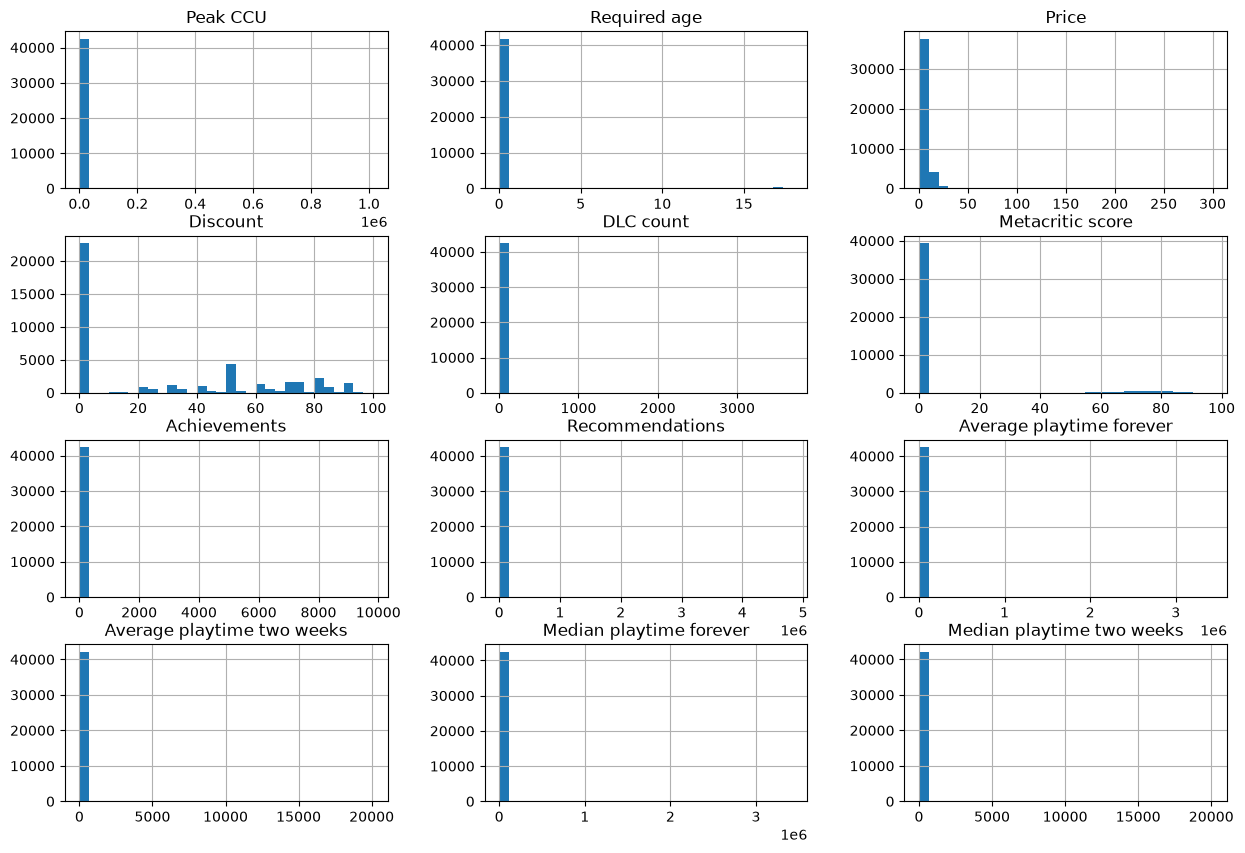

In [132]:
train[numerical_columns].hist(bins=30, figsize=(15, 10))
pass

Из-за скошенности распределений гистограммы малоинформативны: почти все значения попадают в первый столбец. Поэтому построим гистограммы для $\log(1 + x)$ (единица добавляется, так как признаки могут принимать значение 0):

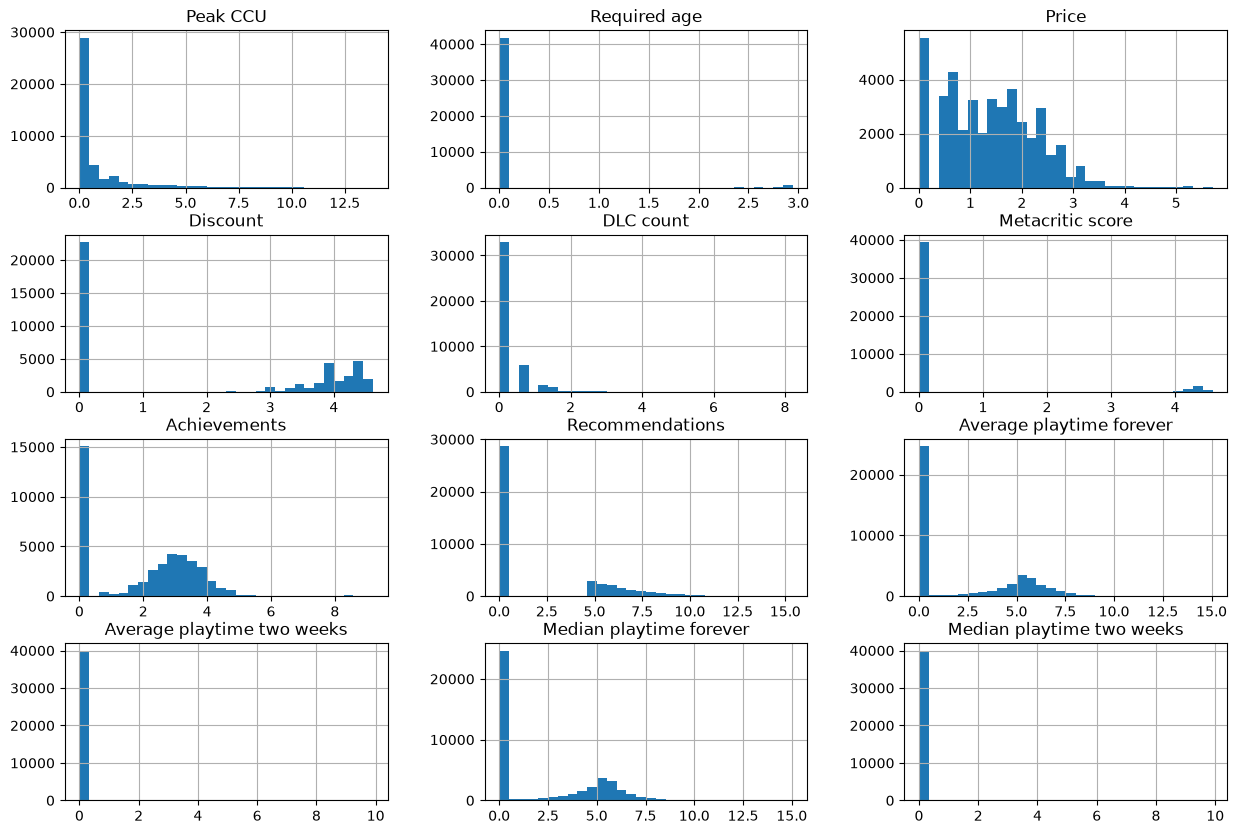

In [133]:
np.log1p(train[numerical_columns]).hist(bins=30, figsize=(15, 10))
pass

После логарифмирования распределения становятся нагляднее: распределение `Price` и ненулевых значений `Achievements`, `Average playtime forever` близки к колоколообразным. Отдельный столбец в нуле у большинства признаков соответствует играм без данных.

Ненулевые значения `Recommendations` начинаются с ~4.6 ($\log 101$): число рекомендаций указывается только для игр, у которых их больше 100.

## Связь признаков с целевой переменной

Сравним распределения некоторых признаков для двух классов с помощью boxplot (по логарифмированным значениям):

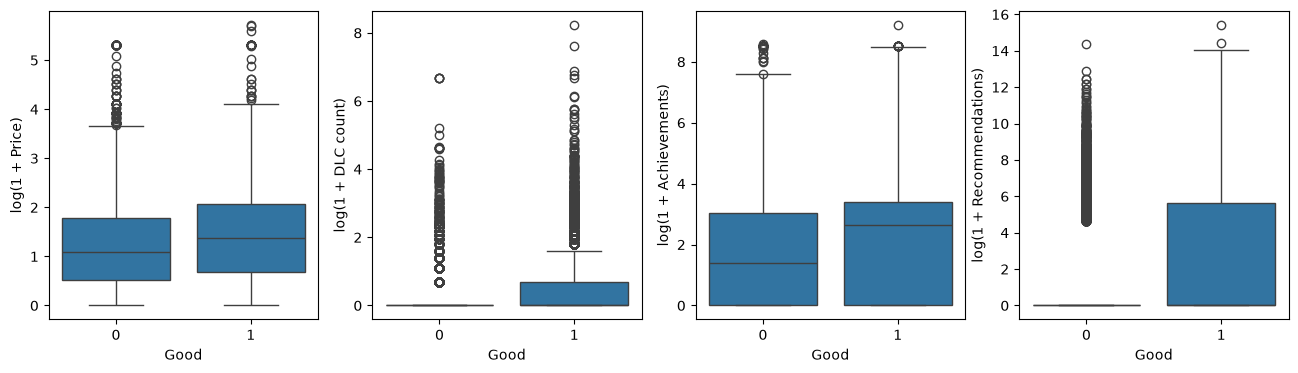

In [134]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, ['Price', 'DLC count', 'Achievements', 'Recommendations']):
    sns.boxplot(x=train['Good'], y=np.log1p(train[c]), ax=ax)
    ax.set_ylabel('log(1 + ' + c + ')')
pass

In [135]:
train.groupby('Good')[['Price', 'DLC count', 'Achievements', 'Recommendations']].quantile([0.5, 0.75])

Price  DLC count  Achievements  Recommendations
Good                                                      
0    0.50   1.99        0.0           3.0              0.0
     0.75   4.99        0.0          20.0              0.0
1    0.50   2.99        0.0          13.0              0.0
     0.75   6.99        1.0          29.0            275.0

У игр класса 1 выше медианная цена (2.99 против 1.99 USD) и медианное число достижений (13 против 3); 75%-квантиль числа дополнений у класса 1 равен 1, у класса 0 - 0.

Рассмотрим бинарные признаки. Поддерживаемые платформы:

In [136]:
train['Windows'].value_counts()

Windows
True     42491
False        5
Name: count, dtype: int64

Windows поддерживают почти все игры, поэтому этот признак неинформативен. Сравним долю игр класса 1 в зависимости от поддержки Mac, Linux и наличия оценки на Metacritic:

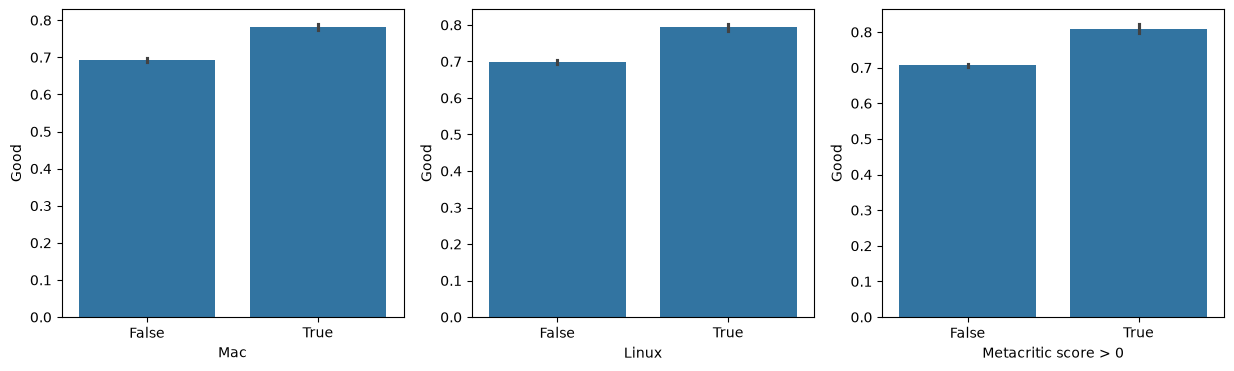

In [137]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(x=train['Mac'], y=train['Good'], ax=axes[0])
sns.barplot(x=train['Linux'], y=train['Good'], ax=axes[1])
sns.barplot(x=train['Metacritic score'] > 0, y=train['Good'], ax=axes[2])
axes[2].set_xlabel('Metacritic score > 0')
pass

Среди игр с поддержкой Mac и Linux доля игр класса 1 выше (~78-79% против ~70%). Также она выше у игр, имеющих оценку на Metacritic (~81%). Вертикальные отрезки на графиках - доверительные интервалы.

Признак `Estimated owners` задаёт интервал числа владельцев игры. Упорядочим интервалы по возрастанию и построим количество игр и долю игр класса 1 для каждого интервала:

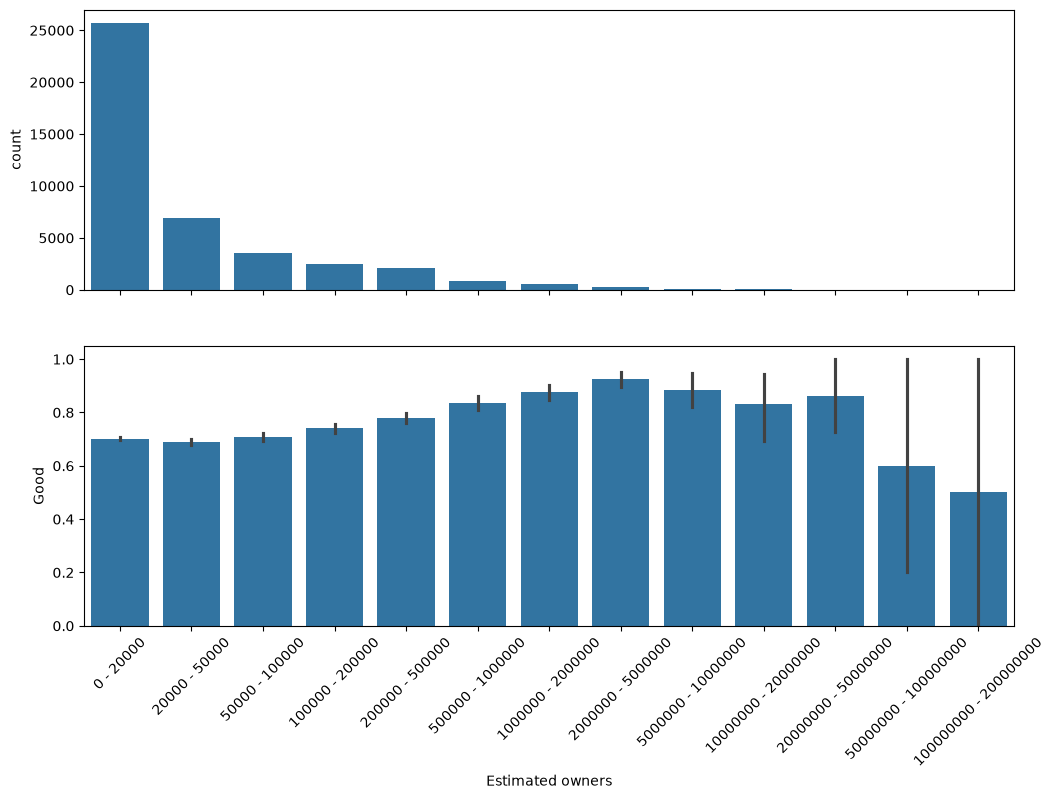

In [138]:
owners_order = sorted(train['Estimated owners'].unique(), key=lambda s: int(s.split(' - ')[0]))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.countplot(x='Estimated owners', data=train, order=owners_order, ax=axes[0])
sns.barplot(x='Estimated owners', y='Good', data=train, order=owners_order, ax=axes[1])
plt.xticks(rotation=45)
pass

Большинство игр (~60%) имеют до 20 тысяч владельцев. С ростом числа владельцев доля игр класса 1 растёт: от ~70% до ~90% у игр с 2-5 млн владельцев. Для самых популярных игр данных мало, поэтому оценка доли для них ненадёжна (широкие доверительные интервалы).

Выделим из даты выхода год и построим количество игр и долю игр класса 1 по годам (рассматриваются годы, для которых в выборке не менее 100 игр):

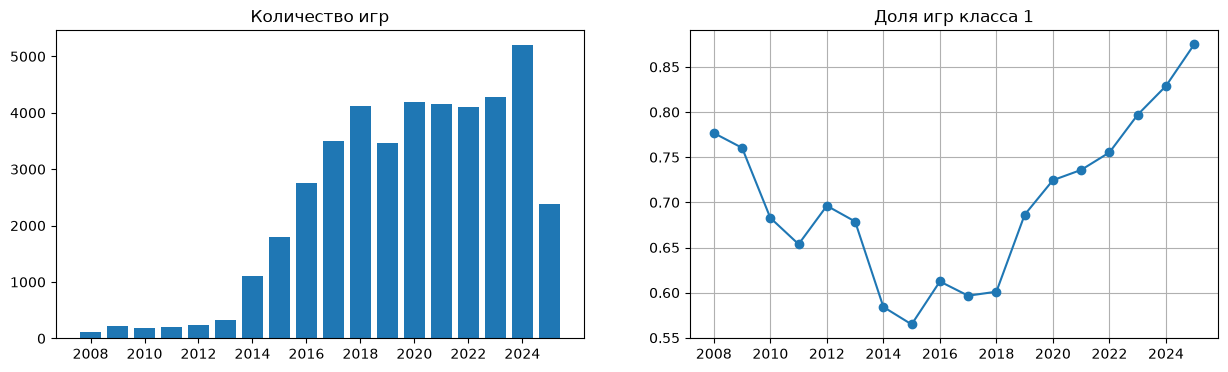

In [139]:
year = pd.to_datetime(train['Release date'], format='mixed').dt.year

year_stats = train.groupby(year)['Good'].agg(['mean', 'size'])
year_stats = year_stats[year_stats['size'] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(year_stats.index, year_stats['size'])
axes[0].set_title('Количество игр')
axes[1].plot(year_stats.index, year_stats['mean'], 'o-')
axes[1].set_title('Доля игр класса 1')
axes[1].grid()
for ax in axes:
    ax.set_xticks(range(2008, 2026, 2))
pass

Количество игр резко выросло после 2014 года. При этом доля игр класса 1 снижалась до ~60% в 2014-2018 годах, а затем стабильно росла до ~88% у игр 2025 года. Таким образом, год выхода связан с целевой переменной, и его стоит использовать как признак.

Столбец `Genres` содержит список жанров через запятую: у одной игры может быть несколько жанров. Разобьём списки на отдельные жанры (метод `explode` создаёт отдельную строку для каждого жанра) и посчитаем долю игр класса 1 для каждого жанра (рассматриваются жанры, встречающиеся не менее 100 раз):

In [140]:
genres = train['Genres'].str.split(',').explode()

genre_stats = pd.DataFrame({'Genre': genres}).join(train['Good']).groupby('Genre')['Good'].agg(['mean', 'size'])
genre_stats = genre_stats[genre_stats['size'] >= 100].sort_values('mean')

genre_stats

,mean,size
Genre,,
Gore,0.330769,130
Violent,0.347222,216
Massively Multiplayer,0.404516,1063
Video Production,0.557252,131
Early Access,0.628851,3473
Utilities,0.639175,388
Animation & Modeling,0.640777,206
Simulation,0.642932,9508
Racing,0.645619,1552


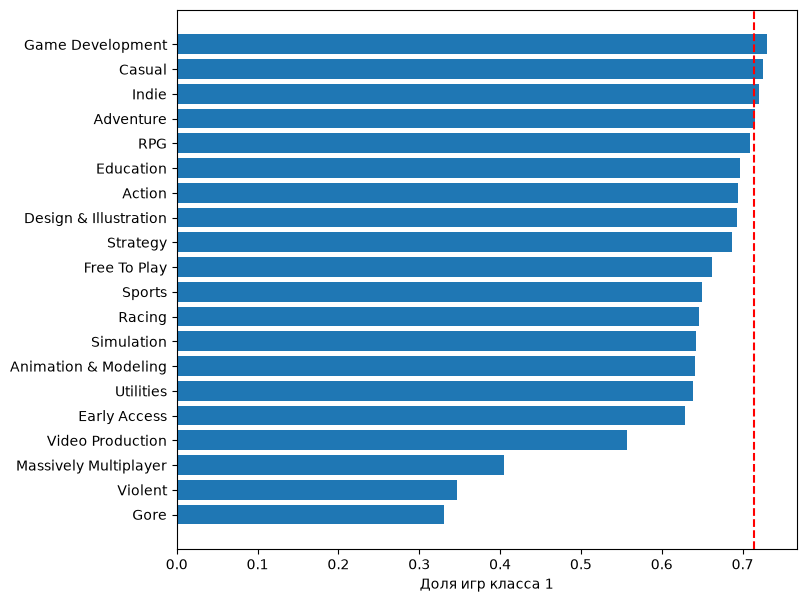

In [141]:
plt.figure(figsize=(8, 7))
plt.barh(genre_stats.index, genre_stats['mean'])
plt.axvline(train['Good'].mean(), color='r', linestyle='--')
plt.xlabel('Доля игр класса 1')
pass

Красная линия - доля игр класса 1 по всей обучающей выборке. Заметно ниже среднего доля класса 1 у жанров `Gore`, `Violent` (~33-35%) и `Massively Multiplayer` (~40%), а также у игр в раннем доступе (`Early Access`, ~63%). Самые распространённые жанры (`Indie`, `Casual`, `Adventure`) близки к среднему значению. Следовательно, жанры несут информацию о целевой переменной; их обработка рассматривается в разделе 6.

## Корреляционная матрица

Вычислим матрицу корреляции для количественных и бинарных признаков:

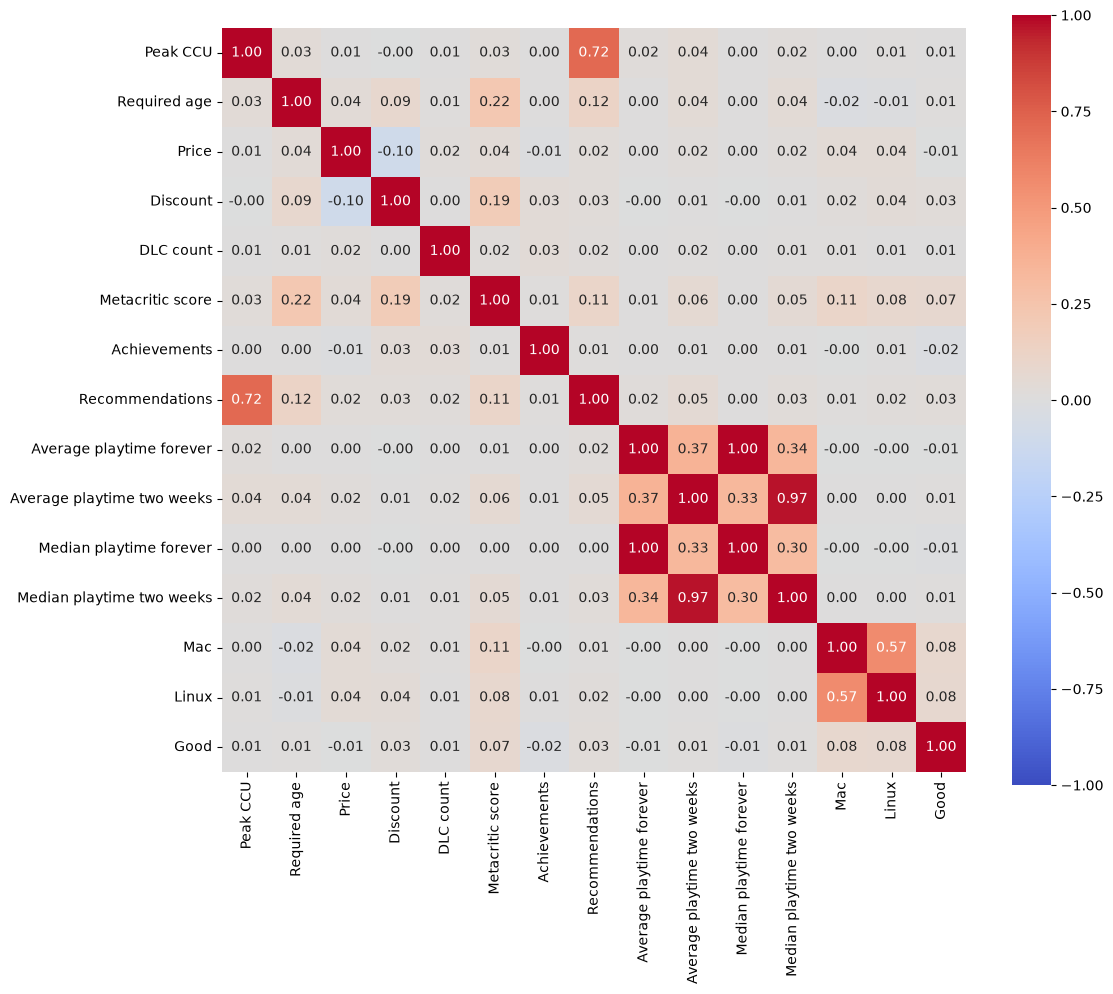

In [142]:
corr_mat = train[numerical_columns + ['Mac', 'Linux', 'Good']].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
pass

Выведем пары признаков с коэффициентом корреляции, большим по модулю 0.5:

In [143]:
corr_mat.where(np.triu(np.abs(corr_mat) > 0.5, k=1)).stack().dropna().sort_values(ascending=False)

Average playtime forever    Median playtime forever      0.995805
Average playtime two weeks  Median playtime two weeks    0.973501
Peak CCU                    Recommendations              0.717796
Mac                         Linux                        0.565308
dtype: float64

- `Average playtime forever` и `Median playtime forever`, а также аналогичные признаки за две недели практически совпадают (0.97-1.00);
- `Peak CCU` и `Recommendations` (0.72) - оба отражают популярность игры;
- `Mac` и `Linux` (0.57) - игры с поддержкой одной из этих платформ часто поддерживают и другую.


При этом коэффициенты корреляции признаков с `Good` близки к 0. Коэффициент корреляции отражает только линейную зависимость, а распределения признаков сильно скошены, поэтому связь, заметная на графиках выше, в нём почти не проявляется.

## Выводы

- Распределения большинства количественных признаков сильно скошены вправо, у многих признаков преобладают нулевые значения; для части признаков ноль означает отсутствие данных.
- Признаки `Movies` (пустой), `Windows` и `Required age` (почти константные) малоинформативны.
- Доля игр класса 1 выше у популярных игр, игр с поддержкой Mac и Linux, с оценкой на Metacritic, с достижениями, а также у недавно вышедших игр; ниже - у жанров `Gore`, `Violent`, `Massively Multiplayer` и `Early Access`.
- Есть сильно коррелированные пары признаков: среднее и медианное время в игре, `Peak CCU` и `Recommendations`, `Mac` и `Linux`.
- Связь каждого отдельного признака с целевой переменной слабая, поэтому качество модели будет определяться совокупностью признаков.

# 4. Обработка выбросов

У количественных признаков есть значения, на несколько порядков превышающие типичные. Посмотрим на верхние квантили:

In [144]:
X_train[numerical_columns].quantile([0.5, 0.99, 0.995, 1])

,Peak CCU,Required age,Price,Discount,DLC count,Metacritic score,Achievements,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks
0.500,0.000,0.0,2.99,0.0,0.00,0.0,11.000,0.000,0.000,0.00,0.000,0.000
0.990,808.650,17.0,29.99,90.0,10.05,84.0,145.000,29619.350,4329.100,522.15,2701.150,511.050
0.995,2250.625,17.0,39.99,92.0,21.00,87.0,296.525,66615.875,8235.975,916.05,4817.675,959.525
1.000,1013936.000,18.0,299.99,100.0,3703.00,97.0,9821.000,4830455.000,3429544.000,20088.00,3429544.000,20088.000


In [145]:
X_train.nlargest(3, 'Peak CCU')[['Name', 'Peak CCU']]

,Name,Peak CCU
AppID,,
730,Counter-Strike 2,1013936
570,Dota 2,623941
578080,PUBG: BATTLEGROUNDS,314682


Большие значения в основном реальны: это самые популярные игры (`Peak CCU` ~1 млн у Counter-Strike 2), игры с тысячами дополнений или достижений. Однако встречаются и явно ошибочные значения, например среднее время в игре ~3.4 млн минут (~6.5 лет непрерывной игры):

In [146]:
X_train.nlargest(5, 'Average playtime forever')[['Name', 'Average playtime forever']]

,Name,Average playtime forever
AppID,,
673900,Avem33,3429544
667120,iTownGamePlay UNIVERSE,1714275
1374480,爱人 Lover,322983
272040,KAMI,196736
1325400,VEGAS Pro 18 Edit Steam Edition,185058


Удалять такие строки нецелесообразно: популярные игры несут полезную информацию, а в тестовой выборке такие игры тоже есть, и для них модель также должна давать ответ. Поэтому вместо удаления ограничим значения сверху 99.5%-квантилем обучающей выборки (значения больше порога заменяются порогом) и применим те же пороги к тестовой выборке.

Признаки `Required age`, `Discount` и `Metacritic score` имеют ограниченный диапазон (возраст, проценты, баллы), поэтому не обрабатываются:

In [147]:
outlier_columns = ['Peak CCU', 'Price', 'DLC count', 'Achievements', 'Recommendations',
                   'Average playtime forever', 'Average playtime two weeks',
                   'Median playtime forever', 'Median playtime two weeks']

upper = X_train[outlier_columns].quantile(0.995)

X_train[outlier_columns] = X_train[outlier_columns].clip(upper=upper, axis=1)
X_test[outlier_columns] = X_test[outlier_columns].clip(upper=upper, axis=1)

upper

Peak CCU                       2250.625
Price                            39.990
DLC count                        21.000
Achievements                    296.525
Recommendations               66615.875
Average playtime forever       8235.975
Average playtime two weeks      916.050
Median playtime forever        4817.675
Median playtime two weeks       959.525
Name: 0.995, dtype: float64

In [148]:
X_train[outlier_columns].describe()

,Peak CCU,Price,DLC count,Achievements,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks
count,42496.000000,42496.000000,42496.000000,42496.000000,42496.000000,42496.000000,42496.000000,42496.000000,42496.000000
mean,27.586693,4.834823,0.578996,19.715146,1114.699769,237.927021,14.625462,169.417610,14.762021
std,192.820857,5.962158,2.087591,32.185421,6042.436027,817.112833,90.662356,505.251104,92.472925
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,2.990000,0.000000,11.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,6.290000,0.000000,27.000000,185.000000,171.000000,0.000000,158.000000,0.000000
max,2250.625000,39.990000,21.000000,296.525000,66615.875000,8235.975000,916.050000,4817.675000,959.525000


Стандартное отклонение признаков заметно уменьшилось (например, у `Peak CCU` с ~6200 до ~190). Однако распределения по-прежнему скошены вправо.

# 5. Обработка пропущенных значений

Посмотрим на количество пропущенных значений в каждом столбце:

In [149]:
X_train.isna().sum()

Name                              0
Release date                      0
Estimated owners                  0
Peak CCU                          0
Required age                      0
Price                             0
Discount                          0
DLC count                         0
About the game                   74
Supported languages               0
Full audio languages              0
Reviews                       34927
Website                       19426
Support email                  6081
Windows                           0
Mac                               0
Linux                             0
Metacritic score                  0
Achievements                      0
Recommendations                   0
Notes                         35842
Average playtime forever          0
Average playtime two weeks        0
Median playtime forever           0
Median playtime two weeks         0
Developers                        1
Publishers                      302
Categories                  

В количественных признаках пропусков нет, они есть только в текстовых столбцах. Столбец `Movies` полностью пустой, поэтому удалим его:

In [150]:
X_train = X_train.drop('Movies', axis=1)
X_test = X_test.drop('Movies', axis=1)

В остальных текстовых столбцах пропуск означает отсутствие значения: у игры нет сайта, цитат прессы, указанных жанров и т. п. Поэтому заполнять их наиболее частым значением некорректно; заменим пропуски пустой строкой:

In [151]:
text_columns = X_train.select_dtypes(exclude=['number', 'bool']).columns

X_train[text_columns] = X_train[text_columns].fillna('')
X_test[text_columns] = X_test[text_columns].fillna('')

Кроме того, в части количественных признаков пропуски закодированы нулём (см. раздел 3).

`Metacritic score` равен 0 у ~93% игр - у таких игр нет оценки критиков. Заменим нули медианой ненулевых значений обучающей выборки и добавим признак-индикатор отсутствия оценки (`add_indicator=True`), так как наличие оценки само по себе связано с целевой переменной:

In [152]:
from sklearn.impute import SimpleImputer

imp = SimpleImputer(missing_values=0, strategy='median', add_indicator=True)
imp.fit(X_train[['Metacritic score']])

X_train[['Metacritic score', 'No Metacritic']] = imp.transform(X_train[['Metacritic score']])
X_test[['Metacritic score', 'No Metacritic']] = imp.transform(X_test[['Metacritic score']])

X_train[['Metacritic score', 'No Metacritic']].head()

,Metacritic score,No Metacritic
AppID,,
1650670,76.0,1.0
1536210,76.0,1.0
108710,83.0,0.0
2568930,76.0,1.0
1147890,81.0,0.0


Время в игре равно 0 у ~58% игр, в основном у игр с числом владельцев до 20 тысяч, для которых статистика, по-видимому, не собирается:

In [153]:
(X_train['Average playtime forever'] == 0).groupby(X_train['Estimated owners']).mean()

Estimated owners
0 - 20000                0.785153
100000 - 200000          0.140244
1000000 - 2000000        0.012987
10000000 - 20000000      0.000000
100000000 - 200000000    0.000000
20000 - 50000            0.445266
200000 - 500000          0.065010
2000000 - 5000000        0.013559
20000000 - 50000000      0.000000
50000 - 100000           0.251064
500000 - 1000000         0.028605
5000000 - 10000000       0.021277
50000000 - 100000000     0.000000
Name: Average playtime forever, dtype: float64

Из-за большой доли таких значений заполнение медианой сильно исказило бы распределение, поэтому нули в признаках времени оставим как отдельное значение «нет данных».

Убедимся, что пропусков не осталось:

In [154]:
X_train.isna().sum().sum(), X_test.isna().sum().sum()

(np.int64(0), np.int64(0))

# 6. Обработка категориальных признаков

Категориальные признаки преобразуем в числовые:

- `Estimated owners` - порядковый признак: заменим интервал его номером в порядке возрастания (`owners_order` из раздела 3);
- `Mac`, `Linux` - бинарные, заменим на 0/1; `Windows` исключим (поддержка присутствует почти всегда);
- `Genres`, `Categories` - у игры может быть несколько значений одновременно, поэтому применим бинаризацию по каждому значению: признак равен 1, если значение есть в списке игры. Чтобы не создавать признаки по редким значениям, оставим жанры, встречающиеся в обучающей выборке не менее 100 раз, и категории - не менее 1000 раз (категорий значительно больше).

Также из нечисловых столбцов получим числовые признаки:

- `Release date` - заменим годом выхода (в разделе 3 видна связь года с целевой переменной);
- `Supported languages`, `Full audio languages`, `Screenshots` - заменим количеством элементов списка;
- `Website`, `Reviews`, `Notes` - заменим бинарными признаками наличия значения.

Остальные нечисловые столбцы (`Name`, `About the game`, `Support email`, `Developers`, `Publishers`, `Tags`) в модели не используются: `Developers` и `Publishers` содержат десятки тысяч различных значений, `Tags` во многом дублируют жанры.

Списки жанров и категорий определяются только по обучающей выборке:

In [155]:
genre_counts = X_train['Genres'].str.get_dummies(sep=',').sum()
genre_list = genre_counts[genre_counts >= 100].index

category_counts = X_train['Categories'].str.get_dummies(sep=',').sum()
category_list = category_counts[category_counts >= 1000].index

owners_codes = {s: i for i, s in enumerate(owners_order)}

len(genre_list), len(category_list)

(20, 27)

Так как одинаковые преобразования нужно применить к обучающей и тестовой выборкам, оформим их в виде функции:

In [156]:
def count_items(s, empty):
    return (s.str.count(',') + 1).where(s != empty, 0)

def transform(X):
    X = X.copy()

    X['Release year'] = pd.to_datetime(X['Release date'], format='mixed').dt.year
    X['Owners'] = X['Estimated owners'].map(owners_codes)

    X['Languages'] = count_items(X['Supported languages'], '[]')
    X['Audio languages'] = count_items(X['Full audio languages'], '[]')
    X['Screenshots count'] = count_items(X['Screenshots'], '')

    for c in ['Website', 'Reviews', 'Notes']:
        X['Has ' + c] = (X[c] != '').astype(int)

    X[['Mac', 'Linux']] = X[['Mac', 'Linux']].astype(int)

    genres = X['Genres'].str.get_dummies(sep=',').reindex(columns=genre_list, fill_value=0).add_prefix('Genre: ')
    categories = X['Categories'].str.get_dummies(sep=',').reindex(columns=category_list, fill_value=0).add_prefix('Category: ')

    X = X.drop(text_columns, axis=1).drop('Windows', axis=1)

    return pd.concat((X, genres, categories), axis=1)

In [157]:
X_train = transform(X_train)
X_test = transform(X_test)

X_train.shape, X_test.shape

((42496, 70), (14166, 70))

Все признаки стали числовыми:

In [158]:
X_train.head()

,Peak CCU,Required age,Price,Discount,DLC count,Mac,Linux,Metacritic score,Achievements,Recommendations,...,Category: Shared/Split Screen PvP,Category: Single-player,Category: Stats,Category: Steam Achievements,Category: Steam Cloud,Category: Steam Leaderboards,Category: Steam Trading Cards,Category: Steam Workshop,Category: Tracked Controller Support,Category: VR Only
AppID,,,,,,,,,,,,,,,,,,,,,
1650670,0.0,0,4.99,0,0,0,0,76.0,40.0,0.0,...,0,1,0,1,0,0,0,0,0,0
1536210,0.0,0,1.99,90,0,0,0,76.0,0.0,139.0,...,0,1,0,0,0,0,0,0,0,0
108710,165.0,0,1.49,90,2,0,0,83.0,67.0,40777.0,...,0,1,0,1,1,0,1,0,0,0
2568930,2.0,0,24.99,0,0,1,1,76.0,50.0,0.0,...,0,1,0,1,1,1,0,0,0,0
1147890,10.0,0,6.99,65,2,1,1,81.0,41.0,254.0,...,0,1,0,1,1,0,0,0,0,0


# 7. Нормализация

Метод ближайших соседей основан на расстояниях между объектами, поэтому без нормализации признаки с большими значениями (например, `Recommendations`) будут полностью определять расстояние, а бинарные признаки практически не будут на него влиять.

Разделим признаки на бинарные (принимают только значения 0 и 1) и количественные:

In [159]:
binary_columns = [c for c in X_train.columns if X_train[c].isin([0, 1]).all()]
scale_columns = [c for c in X_train.columns if c not in binary_columns]

len(binary_columns), len(scale_columns)

(53, 17)

Как видно из раздела 3, распределения большинства количественных признаков сильно скошены вправо. Поэтому перед нормализацией применим к ним преобразование $\log(1 + x)$:

In [160]:
log_columns = ['Peak CCU', 'Price', 'DLC count', 'Achievements', 'Recommendations',
               'Average playtime forever', 'Average playtime two weeks',
               'Median playtime forever', 'Median playtime two weeks',
               'Languages', 'Audio languages', 'Screenshots count']

X_train[log_columns] = np.log1p(X_train[log_columns])
X_test[log_columns] = np.log1p(X_test[log_columns])

Приведём количественные признаки к нулевому среднему и единичному стандартному отклонению. Параметры нормализации вычисляются по обучающей выборке. Бинарные признаки оставим без изменений: их значения 0 и 1 уже соизмеримы с нормализованными признаками.

In [161]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train[scale_columns])

X_train[scale_columns] = scaler.transform(X_train[scale_columns])
X_test[scale_columns] = scaler.transform(X_test[scale_columns])

X_train[scale_columns].describe()

,Peak CCU,Required age,Price,Discount,DLC count,Metacritic score,Achievements,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Release year,Owners,Languages,Audio languages,Screenshots count
count,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04,4.249600e+04
mean,-2.106749e-17,-6.688091e-19,-2.962824e-16,8.192911e-18,1.404499e-17,-1.444293e-15,-1.215560e-16,-8.259792e-17,-4.012854e-18,3.653369e-17,3.979414e-17,1.738904e-17,-3.066088e-14,-5.684877e-18,-7.356900e-17,1.237297e-17,1.074776e-15
std,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00,1.000012e+00
min,-4.882487e-01,-1.324526e-01,-1.526425e+00,-8.407867e-01,-4.560089e-01,-2.436554e+01,-1.225282e+00,-6.683451e-01,-7.949614e-01,-2.365114e-01,-7.993229e-01,-2.367341e-01,-6.567239e+00,-6.076437e-01,-1.690763e+00,-7.228787e-01,-5.404918e+00
25%,-4.882487e-01,-1.324526e-01,-7.547195e-01,-8.407867e-01,-4.560089e-01,5.612997e-02,-1.225282e+00,-6.683451e-01,-7.949614e-01,-2.365114e-01,-7.993229e-01,-2.367341e-01,-5.441040e-01,-6.076437e-01,-8.434410e-01,-7.228787e-01,-7.437261e-01
50%,-4.882487e-01,-1.324526e-01,2.542104e-02,-8.407867e-01,-4.560089e-01,5.612997e-02,3.053294e-01,-6.683451e-01,-7.949614e-01,-2.365114e-01,-7.993229e-01,-2.367341e-01,2.952795e-02,-6.076437e-01,-3.477894e-01,-7.228787e-01,-1.417328e-01
75%,1.032650e-02,-1.324526e-01,7.013297e-01,8.387028e-01,-4.560089e-01,5.612997e-02,8.272338e-01,9.785303e-01,1.049805e+00,-2.365114e-01,1.081207e+00,-2.367341e-01,8.899758e-01,2.856470e-02,6.879707e-01,2.741759e-01,5.473747e-01
max,5.064259e+00,8.267211e+00,2.637868e+00,2.212831e+00,5.607491e+00,7.382631e+00,2.282936e+00,2.831896e+00,2.436345e+00,5.662626e+00,2.346795e+00,5.691856e+00,1.463608e+00,7.026857e+00,3.986667e+00,5.957825e+00,7.086828e+00


У всех количественных признаков обучающей выборки среднее равно 0, а стандартное отклонение - 1.

# 8. Классификатор ближайших соседей

Для решения задачи используем метод $k$ ближайших соседей: объект относится к тому классу, к которому принадлежит большинство из $k$ ближайших к нему объектов обучающей выборки.

Выбор метода обусловлен следующим:
- метод не предполагает какой-либо определённой формы зависимости между признаками и целевой переменной, что важно, так как по разделу 3 связь отдельных признаков с целевой переменной слабая и нелинейная;
- метод прост и имеет один основной гиперпараметр - число соседей $k$, который будет подобран в разделе 9;
- метод служит хорошей базовой моделью для сравнения с другими классификаторами.

При этом у метода есть недостатки, которые важно учитывать в нашей задаче:
- метод чувствителен к масштабу признаков - поэтому в разделе 7 была проведена нормализация;
- при большом числе признаков (у нас 70) расстояния между объектами становятся менее информативными, поскольку каждый признак, в том числе малоинформативный, вносит одинаковый вклад в расстояние;
- для предсказания метод вычисляет расстояния до всех ~42 тысяч объектов обучающей выборки, поэтому работает медленно.

Обучим классификатор с $k = 10$:

In [162]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [163]:
y_train_predict = knn.predict(X_train)
y_test_predict = knn.predict(X_test)

# 9. Ошибки классификатора и подбор числа соседей

Вычислим долю ошибок на обучающей и тестовой выборках для $k = 10$:

In [164]:
err_train = np.mean(y_train != y_train_predict)
err_test = np.mean(y_test != y_test_predict)

err_train, err_test

(np.float64(0.2107492469879518), np.float64(0.2615417196103346))

Матрицы рассогласования для обучающей и тестовой выборок (строки - истинный класс, столбцы - предсказанный; первая строка и первый столбец соответствуют классу 0):

In [165]:
from sklearn.metrics import confusion_matrix

labels = ['0', '1']

display(pd.DataFrame(confusion_matrix(y_train, y_train_predict), index=labels, columns=labels))
display(pd.DataFrame(confusion_matrix(y_test, y_test_predict), index=labels, columns=labels))

,0,1
0,6466,5704
1,3252,27074


,0,1
0,1775,2282
1,1423,8686


In [166]:
print(confusion_matrix(y_test, y_test_predict, normalize='true'))

[[0.43751541 0.56248459]
 [0.14076565 0.85923435]]


По нормированной матрице (каждая строка разделена на число игр соответствующего класса) видно, что модель правильно определяет ~86% игр класса 1, но только ~44% игр класса 0: из-за несбалансированности среди соседей чаще оказываются игры класса 1.

## Подбор числа соседей

Подберём $k$ с помощью кросс-валидации на обучающей выборке (5 частей): для каждого $k$ модель обучается на 4 частях и проверяется на оставшейся, ошибка усредняется. Тестовая выборка при этом не используется.

In [167]:
from sklearn.model_selection import GridSearchCV

k_arr = [1, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

grid = GridSearchCV(KNeighborsClassifier(), param_grid={'n_neighbors': k_arr}, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

best_k = grid.best_params_['n_neighbors']
best_k, 1 - grid.best_score_

(40, np.float64(0.24915283597378246))

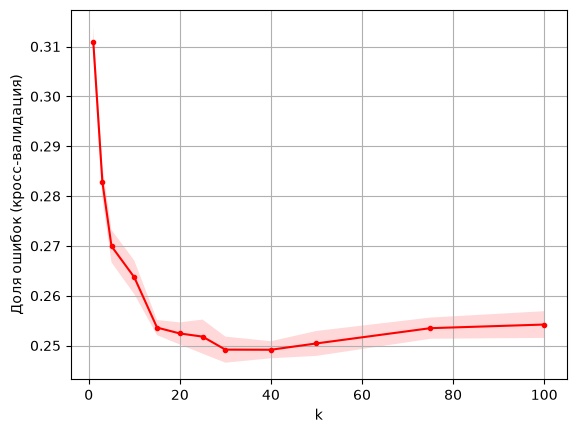

In [168]:
err_arr = 1 - grid.cv_results_['mean_test_score']
std_arr = grid.cv_results_['std_test_score']

plt.plot(k_arr, err_arr, 'r.-')
plt.fill_between(k_arr, err_arr - std_arr, err_arr + std_arr, alpha=0.15, facecolor='red')
plt.xlabel('k')
plt.ylabel('Доля ошибок (кросс-валидация)')
plt.grid()
pass

При малых $k$ модель переобучается: при $k = 1$ каждая игра классифицируется по одной ближайшей игре, и доля ошибок максимальна (~31%). С ростом $k$ ошибка уменьшается и при $k$ от 30 до 40 достигает минимума (~24.9%; значения практически совпадают), после чего начинает медленно расти: модель становится слишком "грубой" и всё чаще предсказывает преобладающий класс.

Обучим модель с оптимальным $k$:

In [169]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

y_train_predict = knn.predict(X_train)
y_test_predict = knn.predict(X_test)

err_train = np.mean(y_train != y_train_predict)
err_test = np.mean(y_test != y_test_predict)

err_train, err_test

(np.float64(0.23557511295180722), np.float64(0.253423690526613))

Матрицы рассогласования для обучающей и тестовой выборок (строки - истинный класс, столбцы - предсказанный). Во второй таблице каждая строка разделена на число игр соответствующего класса:

In [170]:
from sklearn.metrics import confusion_matrix

print('Обучающая выборка:')
display(pd.DataFrame(confusion_matrix(y_train, y_train_predict)))
display(pd.DataFrame(confusion_matrix(y_train, y_train_predict, normalize='true')).round(2))

print('Тестовая выборка:')
display(pd.DataFrame(confusion_matrix(y_test, y_test_predict)))
display(pd.DataFrame(confusion_matrix(y_test, y_test_predict, normalize='true')).round(2))

Обучающая выборка:


,0,1
0,4189,7981
1,2030,28296


,0,1
0,0.34,0.66
1,0.07,0.93


Тестовая выборка:


,0,1
0,1245,2812
1,778,9331


,0,1
0,0.31,0.69
1,0.08,0.92


При $k = 40$ доля ошибок на тестовой выборке снизилась с ~26.2% до ~25.3%, а разница между ошибками на обучающей (~23.6%) и тестовой выборках уменьшилась, то есть модель меньше переобучена.

Однако модель правильно определяет лишь ~31% игр класса 0 (при $k = 10$ - ~44%): снижение доли ошибок достигнуто за счёт того, что модель чаще предсказывает преобладающий класс.

# 10. Сравнение с другими классификаторами

Сравним метод ближайших соседей с более сложными методами - случайным лесом и градиентным бустингом. Оба метода строят ансамбль решающих деревьев и, в отличие от $k$NN, сами определяют, какие признаки важнее. Для сравнения добавим также предсказание класса 1 для всех игр:

In [171]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

results = pd.DataFrame(columns=['train', 'test'])
results.loc['Всегда класс 1'] = (np.mean(y_train != 1), np.mean(y_test != 1))
results.loc['kNN, k = ' + str(best_k)] = (err_train, err_test)

rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
results.loc['Random Forest'] = (np.mean(y_train != rf.predict(X_train)), np.mean(y_test != rf.predict(X_test)))

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
results.loc['Gradient Boosting'] = (np.mean(y_train != gb.predict(X_train)), np.mean(y_test != gb.predict(X_test)))

results

,train,test
Всегда класс 1,0.286380,0.286390
"kNN, k = 40",0.235575,0.253424
Random Forest,0.001035,0.235988
Gradient Boosting,0.235175,0.245023


Нормированные матрицы рассогласования на тестовой выборке для случайного леса и градиентного бустинга:

In [172]:
display(pd.DataFrame(confusion_matrix(y_test, rf.predict(X_test), normalize='true')).round(2))
display(pd.DataFrame(confusion_matrix(y_test, gb.predict(X_test), normalize='true')).round(2))

,0,1
0,0.36,0.64
1,0.07,0.93


,0,1
0,0.31,0.69
1,0.06,0.94


Случайный лес почти без ошибок классифицирует обучающую выборку (~0.1%), то есть сильно переобучен, но при этом даёт наименьшую ошибку на тестовой выборке (~23.6%). Градиентный бустинг переобучен значительно меньше (~23.5% и ~24.5%).

Однако все методы улучшают результат по сравнению с предсказанием класса 1 для всех игр (~28.6%) лишь на 4-5%, а игры класса 0 правильно определяют только в 31-36% случаев. Следовательно, качество ограничено не методом, а самими признаками: по имеющимся данным оценку игры можно предсказать лишь приблизительно.

Посмотрим, какие признаки градиентный бустинг считает наиболее важными:

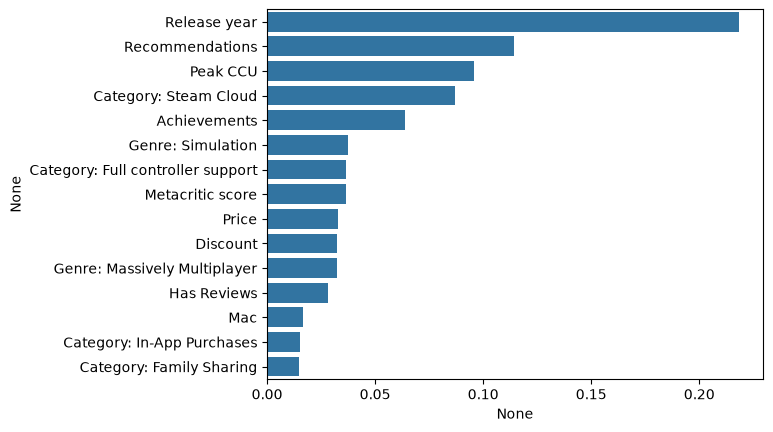

In [173]:
importances = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values(ascending=False)

sns.barplot(y=importances.index[:15], x=importances[:15], orient='h')
pass

Наиболее важными оказались год выхода, признаки популярности (`Recommendations`, `Peak CCU`), наличие облачных сохранений (`Steam Cloud`) и число достижений (по оценке градиентного бустинга).

# Выводы

- Решалась задача бинарной классификации: по данным об игре в Steam определить, будет ли доля положительных отзывов не меньше 70%. Использовались игры с не менее чем 10 отзывами (~57 тысяч), классы несбалансированы (~71% / 29%).
- Данные потребовали предобработки: исправлен сдвиг столбцов при чтении, ограничены выбросы (значения выше 99.5%-квантиля), обработаны пропуски, в том числе закодированные нулём, категориальные признаки преобразованы в числовые (итого 70 признаков), количественные признаки логарифмированы и нормализованы.
- Метод $k$ ближайших соседей при оптимальном $k = 40$ даёт долю ошибок ~25.3% на тестовой выборке против ~28.6% при предсказании класса 1 для всех игр. При малых $k$ модель переобучается, при больших - всё чаще предсказывает преобладающий класс.
- Из-за несбалансированности классов модель правильно определяет ~92% игр класса 1, но только ~31% игр класса 0; с ростом $k$ доля ошибок уменьшается за счёт ухудшения распознавания класса 0.
- Случайный лес и градиентный бустинг дают несколько лучший результат (~23.6-24.5%), однако также плохо распознают игры класса 0. Таким образом, качество ограничено не методом, а признаками: цена, жанры, платформы и популярность игры лишь частично определяют её оценку игроками.
- Наиболее важными признаками оказались год выхода, популярность игры и число достижений (по оценке иных классификаторов).